--- Fit Results for 25% Glycerol $T_1$ Recovery ---
Calculated T1: 300.00 ± 2.78 ms
Fitted plateau (a): 2.33 ± 0.03 V
Fitted amplitude (k): 6.80 ± 0.02 V



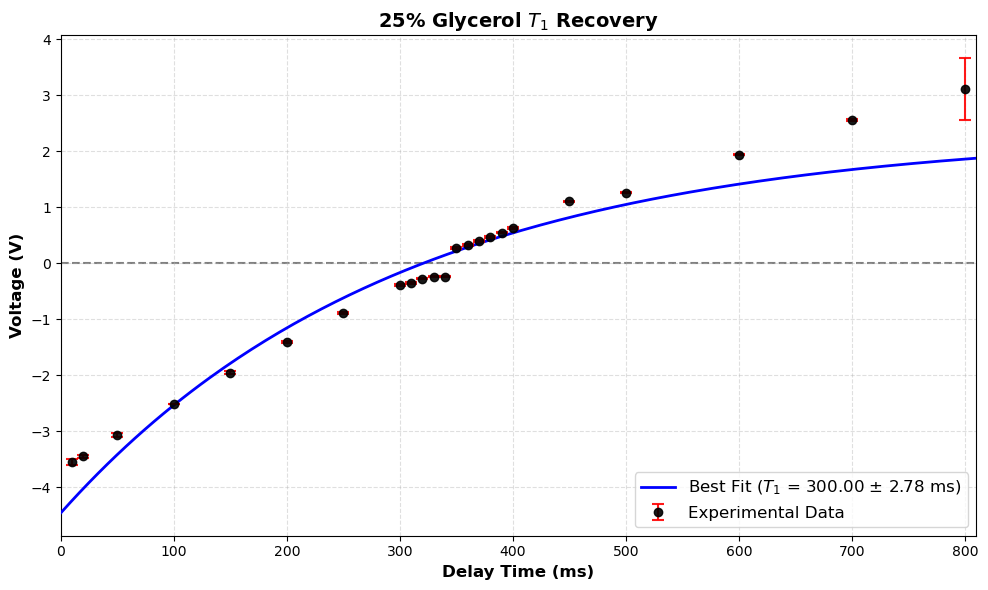

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path

# Process 90% Glycerol using your exact file path

# Process 90% Glycerol using your exact file path
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\25% Glyerol\T1.csv",  '25% Glycerol $T_1$ Recovery')

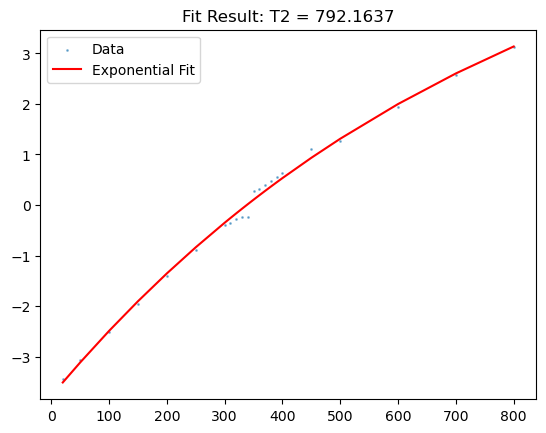

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Load
file = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\25% Glyerol\T1.csv"
data = pd.read_csv(file, encoding='windows-1252', skiprows=1, usecols=[0, 1])
data.columns = ['time', 'voltage']

# 2. Clean
data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
data['time'] = pd.to_numeric(data['time'], errors='coerce')
data = data.dropna()

# 3. Fit directly to the raw data (No peak searching)
def decay_func(t, A, T_2, C):
    return A * np.exp(-t / T_2) + C

# Shift time to start at 0 for the fit
t_fit = data['time'] - data['time'].iloc[0]
v_fit = data['voltage']

# Guesses: Amplitude, T2 (decay constant), Offset
p0 = [v_fit.max() - v_fit.min(), t_fit.max()/2, v_fit.min()]

popt, _ = curve_fit(decay_func, t_fit, v_fit, p0=p0)

# 4. Plot Results
plt.scatter(data['time'], data['voltage'], s=1, label='Data', alpha=0.5)
plt.plot(data['time'], decay_func(t_fit, *popt), color='red', label='Exponential Fit')
plt.legend()
plt.title(f"Fit Result: T2 = {popt[1]:.4f}")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. CONSTANTS
conc = "12.5" 
visc_pa_s = 0.00135  # 1.35 cP
tau = 0.002          # 2ms
G = 0.01             
kB, Temp, gamma, r_h = 1.38e-23, 298.15, 2.675e8, 3.1e-10

# Physics Calculation
D = (kB * Temp) / (6 * np.pi * visc_pa_s * r_h)
diff_penalty = (1/3) * (gamma**2) * (G**2) * D * (tau**2)

# 2. LOAD DATA
path = rf"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\{conc}% glycerol\T2.csv"
print("Loading data...")
try:
    df = pd.read_csv(path, encoding='windows-1252', skiprows=1).apply(pd.to_numeric, errors='coerce').dropna()
    t = df.iloc[:, 0].values
    v = df.iloc[:, 1].values
    print(f"Data loaded: {len(t)} points found.")
except Exception as e:
    print(f"FAILED TO LOAD: {e}")
    exit()

# 3. NO-LOOP PEAK EXTRACTION
# We just find the global max, and then take points every '2*tau' seconds.
start_idx = np.argmax(v)
dt = t[1] - t[0]
points_between_echoes = int((2 * tau) / dt)

# Grab indices mathematically rather than searching
indices = np.arange(start_idx, len(v), points_between_echoes)
# Limit to the first 99 echoes
indices = indices[:99]

t_peaks = t[indices]
v_peaks = v[indices]

# 4. THE MODEL
def model(t_rel, A, T2):
    return A * np.exp(-t_rel * (1/T2 + diff_penalty))

t_fit = t_peaks - t_peaks[0]

# 5. EXECUTE FIT
print("Starting fit...")
try:
    popt, _ = curve_fit(model, t_fit, v_peaks, p0=[v_peaks[0], 0.05])
    print(f"SUCCESS! True T2: {popt[1]*1000:.2f} ms")
    
    plt.plot(t, v, alpha=0.3, label='Raw Trace')
    plt.scatter(t_peaks, v_peaks, color='red', label='Sampled Echoes')
    plt.plot(t_peaks, model(t_fit, *popt), 'k--', label='Physics Fit')
    plt.legend()
    plt.show()
except Exception as e:
    print(f"FIT ERROR: {e}")